# NN for handwritten digits recognition

## Packages

In [1]:
import os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset, load_from_disk

## Dataset Loading

In [2]:
dataset_path = Path("dataset")

if dataset_path.exists():
    dataset = load_from_disk(str(dataset_path))
else:
    dataset = load_dataset("ylecun/mnist")
    dataset_path.parent.mkdir(parents=True, exist_ok=True)
    dataset.save_to_disk(str(dataset_path))

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 10000
    })
})


## Overview of an example image

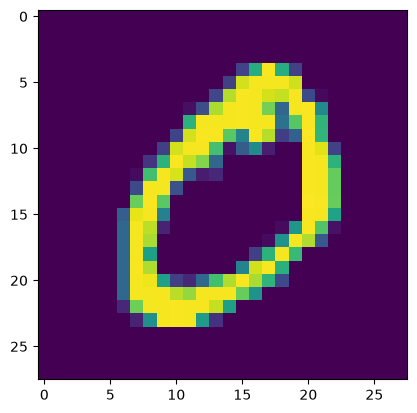

['image', 'label']


In [3]:
# Get an image from the training split
example = dataset["train"][1]

# Display the image
plt.imshow(example["image"])
plt.show()
print(dataset["train"].column_names)

## Spliting the datasets

In [4]:
train = dataset["train"]
test = dataset["test"]

X_train, y_train = train["image"], train["label"]
X_test, y_test = test["image"], test["label"]

print(X_train)
print(len(X_train))

print(y_train)
print(len(y_train))

print("-----------------------------")

print(X_test)
print(len(X_test))

print(y_test)
print(len(y_test))

Column([<PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB303C50>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB278410>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB619810>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB619450>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB619090>, ...])
60000
Column([5, 0, 4, 1, 9, ...])
60000
-----------------------------
Column([<PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB278410>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB2782D0>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB619810>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB619450>, <PIL.PngImagePlugin.PngImageFile image mode=L size=28x28 at 0x70FAEB619090>, ...])
10000
Column([7, 2, 1, 0, 4, ...])
10000


## Normalization and Vectorization over the datasets

In [5]:
# X_train = np.array([np.array(img) for img in X_train])
# X_test = np.array([np.array(img) for img in X_test])

# y_train = np.array(y_train)
# y_test = np.array(y_test)

def convert(
    data,
    split: str
):
    save_dir = Path("dataset/hdr_numpy")
    save_dir.mkdir(parents=True, exist_ok=True)

    x_path = save_dir / f"x_{split}.npy"
    y_path = save_dir / f"y_{split}.npy"

    # Already converted -> load directly
    if x_path.exists() and y_path.exists():
        print(f"Loading cached {split} dataset...")

        x = np.load(x_path, mmap_mode="r")
        y = np.load(y_path, mmap_mode="r")

        return x, y

    n = len(data)

    x = np.stack(
        [np.asarray(img, dtype=np.float32).reshape(1, 784) for img in data["image"]]
    ) / 255.0

    y = np.asarray(data["label"], dtype=np.int8)

    out_x = np.lib.format.open_memmap(x_path, mode="w+", dtype=np.float32, shape=x.shape)
    out_y = np.lib.format.open_memmap(y_path, mode="w+", dtype=np.int8, shape=y.shape)

    # copie every value from the in-memory array
    out_x[:] = x
    out_y[:] = y

    # save to disk
    out_x.flush()
    out_y.flush()

    print(f"Saved {split} dataset to {save_dir}")

    return out_x, out_y
    

# print("TRAIN")
# print("X shape:", X_train.shape)
# print("y shape:", y_train.shape)

# print("Single image shape:", X_train[0].shape)
# print("X dtype:", X_train.dtype)
# print("y dtype:", y_train.dtype)

# print("Pixel range:", X_train.min(), X_train.max())

# print("First image:")
# print(X_train[0])

# print("First label:")
# print(y_train[0])

# print("-" * 70)

# print("TEST")
# print("X shape:", X_test.shape)
# print("y shape:", y_test.shape)


# def convert(
#     data,
#     split: str
# ):
#     """
#         The convertion/normalization func is for small datasets.
#         For bigger ones, it should be considered something else.
#     """
#     save_dir = Path("dataset/hdr_numpy")
#     save_dir.mkdir(parents=True, exist_ok=True)

#     x_path = save_dir / f"x_{split}.npy"
#     y_path = save_dir / f"y_{split}.npy"

#     # Already converted -> load directly
#     if x_path.exists() and y_path.exists():
#         print(f"Loading cached {split} dataset...")

#         x = np.load(x_path, mmap_mode="r")
#         y = np.load(y_path, mmap_mode="r")

#         return x, y

#     print(f"Converting {split}...")

#     n = len(data)

#     # Create the .npy files directly on disk
#     x = np.lib.format.open_memmap(
#         x_path,
#         mode="w+",
#         dtype=np.float32,
#         shape=(n, 1, 784),
#     )

#     y = np.lib.format.open_memmap(
#         y_path,
#         mode="w+",
#         dtype=np.int8,
#         shape=(n,),
#     )

#     data = data.with_format(
#         "numpy",
#         columns=["image", "label"],
#     )

#     for start in range(0, n):
#         end = min(start, n)

#         batch = data[start:end]

#         images = batch["image"].reshape(-1, 1, 784)

#         # uint8 [0, 255] -> float32 [0.0, 1.0]
#         # black 0   -> 0.0
#         # white 255 -> 1.0
#         x[start:end] = images.astype(np.float32) / 255.0

#         y[start:end] = batch["label"]

#     # everything is written to disk.
#     x.flush()
#     y.flush()

#     print(f"Saved {split} dataset to {save_dir}")

#     return x, y


# Normalized and Vectorized
X_train_norm, y_train_norm = convert(train, "train")
X_test_norm, y_test_norm = convert(test, "test")


# Check the results
print("TRAIN")
print("x shape:", X_train_norm.shape)
print("y shape:", y_train_norm.shape)

print("single image shape:", X_train_norm[0].shape)

print("x dtype:", X_train_norm.dtype)
print("y dtype:", y_train_norm.dtype)

print("pixel range:", X_train_norm.min(), y_train_norm.max())

print("first image:")
print(X_train_norm[0])

print("first label:")
print(y_train_norm[0])

print("-----------------------------------------------------------------------")

print("TEST")
print("x shape:", X_test_norm.shape)
print("y shape:", y_test_norm.shape)

Loading cached train dataset...
Loading cached test dataset...
TRAIN
x shape: (60000, 1, 784)
y shape: (60000,)
single image shape: (1, 784)
x dtype: float32
y dtype: int8
pixel range: 0.0 9
first image:
[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0. 

## NN functions

In [ ]:
# activation function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def propagate(w, b, X, Y):
    h1 = sigmoid(w @ X + b)

    
    

